# Perform linear regression to identify metabolites with differing abundances in those using antibiotics
These regressions will have all covariates selected in `get_abx_use_covariates` notebook. In addition, we will be able to look at those who use antibiotics in the last three versus the last twelve months. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import arivale_data_interface as adi
adi.apply_isb_config()

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
from regression_functions import *

In [2]:
# adi.get_snapshot("medication_dosages")

# Import and process data

In [3]:
# Read and sort abx use data
abx_covar = pd.read_csv("../data/abx_recency_covariates_all.csv")
abx_covar = abx_covar.sort_values(by="days_in_program")

# Read and sort metab information
metabolites = adi.get_snapshot("metabolomics_corrected").sort_values(by="days_in_program")

misanns_ids = {'100020423':'100022485',
               '100020419':'100022482',
               '100020425':'100022480',
               '100020427':'100022479'}
metabolites = metabolites.rename(misanns_ids, axis='columns')

metabolite_features = metabolites.columns[8:]
metabolites.days_in_program = metabolites.days_in_program.astype("float64")

In [4]:
# abx_covar

In [5]:
covar_columns = abx_covar.columns.tolist()

In [6]:
anns_snapshot = pd.read_csv("../data/metabolites_snapshot_updated.csv")

In [7]:
# # Run this cell for generating a table of id and days for Noa for metBMI
# mets_ids_days = metabolites.copy()
# mets_ids_days.rename(columns={'days_in_program':'days_in_program_mets'}, inplace=True)

# mets = pd.merge_asof(
#     abx_covar, mets_ids_days, 
#     by="public_client_id", 
#     left_on="days_in_program",
#     right_on="days_in_program_mets",
#     direction="nearest", 
#     tolerance=30.0).dropna(subset=metabolite_features, how="all")

# mets_ids_days_df = mets[['public_client_id','days_in_program_mets']].copy()
# mets_ids_days_df.to_csv('data/ids_days_for_metBMI.csv', index=False)

In [8]:
# anns_snapshot[anns_snapshot.CHEMICAL_NAME == 'alpha-hydroxyisocaproate']

In [9]:
metabolites_merged = pd.merge_asof(
    abx_covar, metabolites, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30.0).dropna(subset=metabolite_features, how="all")
metabolite_features = metabolites.columns[metabolites.columns.isin(metabolite_features)]
metabolites_merged.head()

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,999953114,999953157,999953172,999953266,999953267,999954831,999954832,999954834,999954839,999954840
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,0.736626,1.928746,NaN,1.151177,0.899924,0.982119,0.992174,1.020387,0.369896,1.418072
4,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,0.452953,NaN,NaN,1.864759,1.299824,1.037411,1.049852,1.109848,NaN,0.789232
5,01324699,0.059337,-0.024547,-0.040044,0.094414,0.034026,-2.0,No,No,three,...,0.714330,0.749277,0.910968,2.190841,1.156268,0.941816,0.736709,0.773792,1.650485,1.782973
6,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,0.649365,0.882981,NaN,NaN,1.404256,0.987746,1.037036,0.877633,NaN,0.826977
7,01994483,0.054177,0.014071,0.020539,-0.093049,-0.005232,0.0,No,No,none,...,1.092669,0.894790,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.782441


In [10]:
# Getting rid of the most sparse columns
bad = metabolites_merged[metabolite_features].isnull().sum() / metabolites_merged.shape[0] > 0.3
metabolite_features = bad[~bad].index
metabolites_merged = metabolites_merged.drop(columns=bad[bad].index)
metabolites_merged.shape

(1599, 996)

In [11]:
# Standardizing data
metabolites_merged[metabolite_features] = np.log(metabolites_merged[metabolite_features])
metabolites_merged[metabolite_features] = metabolites_merged[metabolite_features].apply(lambda x: (x - x.mean()) / x.std())
metabolites_merged.rename(columns=dict(zip(metabolite_features, "metabolite_" + metabolite_features)), inplace=True)
metabolite_features = "metabolite_" + metabolite_features
metabolites_all = metabolite_features

In [12]:
assert (metabolites_merged[metabolite_features].mean().abs() < 1e-6).all()

In [13]:
metabolites_merged['abx_recency'].value_counts() #.tolist()

abx_recency
none      1031
twelve     352
three      216
Name: count, dtype: int64

In [14]:
len(metabolites_all)

969

# Run Regressions

In [15]:
metabolites_merged.to_csv("../data/metabolites_merged_used_for_regressions.csv", index=False)

In [16]:
# For all regressions in this notebook we will use the same features and df
args = metabolite_features
df = metabolites_merged.set_index(['public_client_id','days_in_program'])

In [17]:
len(metabolite_features)

969

In [18]:
metabolite_features

Index(['metabolite_35', 'metabolite_50', 'metabolite_55', 'metabolite_62',
       'metabolite_93', 'metabolite_98', 'metabolite_111', 'metabolite_112',
       'metabolite_132', 'metabolite_136',
       ...
       'metabolite_999952843', 'metabolite_999952865', 'metabolite_999952867',
       'metabolite_999952870', 'metabolite_999952877', 'metabolite_999952909',
       'metabolite_999953114', 'metabolite_999953157', 'metabolite_999953267',
       'metabolite_999954840'],
      dtype='object', length=969)

array([[<Axes: title={'center': '0'}>]], dtype=object)

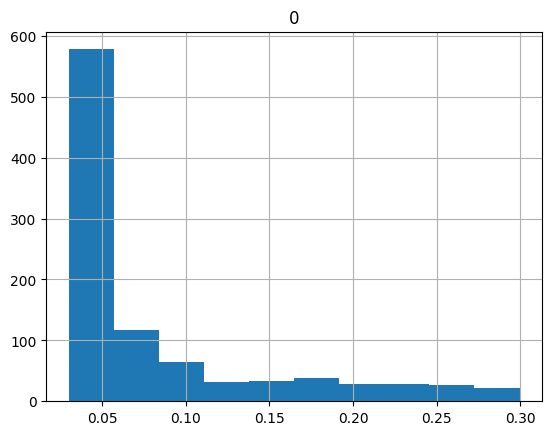

In [19]:
pd.DataFrame(metabolites_merged[metabolite_features].isna().sum() / metabolites_merged[metabolite_features].shape[0]).hist()

In [20]:
formula_mets = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
               "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) +"
               "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")
# Use this as sens analysis to better correct for health status
# I.e. some folks w/ T2D may be managed by diet and exercise only
formula_mets_dysreg = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
               "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) + C(hx_t2dm) + C(hx_gestational) +"
               "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")
abx_term_three = "C(abx_recency_three)[T.1]"
abx_term_twelve = "C(abx_recency_twelve)[T.1]"
chol_term = "C(meds_cholesterol)[T.Yes]"
sugar_term = "C(meds_blood_sugar)[T.Yes]"

## Three month regression

In [21]:
tests_threemo = run_tests(args, df, formula_mets, abx_term_three)
tests_threemo_dysreg = run_tests(args, df, formula_mets_dysreg, abx_term_three)

Output()

Output()

In [22]:
sig_three = tests_threemo[tests_threemo["q"]<0.1].sort_values(by='q')

In [23]:
# Merge onto annotations
tests_three_anns = pd.merge(tests_threemo, anns_snapshot, on="feature")
tests_three_anns_sig = (tests_three_anns[tests_three_anns["q"]<0.1]
                        [['beta', 'se', 'n', 'q','CHEMICAL_NAME', 'SUB_PATHWAY']])

tests_three_anns_dys = pd.merge(tests_threemo_dysreg, anns_snapshot, on="feature")
tests_three_anns_sig_dys = (tests_three_anns_dys[tests_three_anns_dys["q"]<0.1]
                        [['beta', 'se', 'n', 'q','CHEMICAL_NAME', 'SUB_PATHWAY']])

In [24]:
larger_cohort_sig = set(tests_three_anns_sig['CHEMICAL_NAME'])
add_dys_sig = set(tests_three_anns_sig_dys['CHEMICAL_NAME'])

In [25]:
larger_cohort_sig.intersection(add_dys_sig)

{'2-hydroxy-3-methylvalerate',
 '2-hydroxybutyrate/2-hydroxyisobutyrate',
 '2-piperidinone',
 '3-(3-hydroxyphenyl)propionate',
 '3-(4-hydroxyphenyl)lactate',
 '3-hydroxy-2-ethylpropionate',
 '3-hydroxydecanoate',
 '3-hydroxylaurate',
 '3-hydroxymyristate',
 '3-hydroxyoctanoate',
 '3-phenylpropionate (hydrocinnamate)',
 '4-hydroxyhippurate',
 '4-methyl-2-oxopentanoate',
 '5-hydroxyhexanoate',
 '5alpha-androstan-3beta,17alpha-diol disulfate',
 'X - 12216',
 'X - 12544',
 'X - 15728',
 'X - 17335',
 'X - 21353',
 'acetylcarnitine (C2)',
 'alpha-hydroxyisocaproate',
 'alpha-hydroxyisovalerate',
 'alpha-ketobutyrate',
 'cinnamoylglycine',
 'dodecadienoate (12:2)*',
 'glutarate (C5-DC)',
 'hippurate',
 'hydantoin-5-propionate',
 'indolepropionate',
 'isoursodeoxycholate',
 'phenyllactate (PLA)'}

In [26]:
add_dys_sig - larger_cohort_sig

{'3-hydroxyhexanoate', 'citrate'}

In [27]:
larger_cohort_sig - add_dys_sig

set()

In [28]:
# tests_three_anns_sig_dys.sort_values(by=['beta','q'])

In [29]:
# # Checks which bile acids were tested
# tests_three_anns.dropna()[tests_three_anns['SUB_PATHWAY'].dropna().str.contains("Bile")]['CHEMICAL_NAME'].tolist()
# tests_three_anns.dropna()[tests_three_anns['SUB_PATHWAY'].dropna().str.contains("Bile")]

## Regressions to extract betas from 3-12 months

In [30]:
# Now find the betas for 12 months
tests_twelvemo = run_tests(args, df, formula_mets, abx_term_twelve)

Output()

In [31]:
tests_twelve_anns = pd.merge(tests_twelvemo, anns_snapshot, on="feature")
tests_twelve_anns_sig = (tests_twelve_anns[tests_twelve_anns["q"]<0.1]
                         [['beta','se','n', 'q', 'CHEMICAL_NAME', 'SUB_PATHWAY']])

In [32]:
sig_hists_twelve_list = tests_twelve_anns[tests_twelve_anns["q"]<0.1]['feature'].tolist()

In [33]:
# For supplement:
tests_three_anns.to_csv("../data/mets_regressions_all_coef_three.csv")
tests_twelve_anns.to_csv("../data/mets_regressions_all_coef_twelve.csv")

### Save lists of significant hits

In [34]:
# Includes metabolite_ prefix
sig_hists_twelve_list = tests_twelve_anns[tests_twelve_anns["q"]<0.1]['feature'].tolist()
sig_hists_three_list = tests_three_anns[tests_three_anns["q"]<0.1]['feature'].tolist()
sig_hits_metab_number = list(set(sig_hists_three_list + sig_hists_twelve_list))

# Just metabolon id
sig_metabolon_ids = [s.split("_", 1)[1] for s in sig_hits_metab_number]

# By chemical name
all_sig_metabs_names = list(set(list(tests_twelve_anns_sig.CHEMICAL_NAME) +
                                list(tests_three_anns_sig.CHEMICAL_NAME)))

In [35]:
#all_sig_metabs_names
for_sarah = tests_twelve_anns[tests_twelve_anns.feature.isin(
    sig_hits_metab_number)][['feature','CHEMICAL_NAME','HMDB']].copy()

In [36]:
for_sarah.to_csv('../data/mets_for_SOL_replication.csv')

## Extract beta coefficients associated with cholesterol and blood sugar lowering medication use

In [37]:
tests_chol = run_tests(args, df, formula_mets, chol_term)
tests_chol_anns = pd.merge(tests_chol, anns_snapshot, on="feature")
tests_chol_anns_subset = tests_chol_anns[tests_chol_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]

Output()

In [38]:
tests_sugar = run_tests(args, df, formula_mets, sugar_term)
tests_sugar_anns = pd.merge(tests_sugar, anns_snapshot, on="feature")
tests_sugar_anns_subset = tests_sugar_anns[tests_sugar_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]

Output()

## Get beta and q-value dataframes for plotting in R

In [39]:
metabs_betas = (tests_three_anns[tests_three_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]
                [['CHEMICAL_NAME','beta']].rename(columns={'beta':'abx_three'}))

# Add twelve month betas
metabs_betas = metabs_betas.merge(tests_twelve_anns[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'abx_twelve'})

metabs_betas = metabs_betas.merge(tests_chol_anns_subset[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'chol_meds'})

metabs_betas = metabs_betas.merge(tests_sugar_anns_subset[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'blood_sugar_meds'})

metabs_betas

,CHEMICAL_NAME,abx_three,abx_twelve,chol_meds,blood_sugar_meds
0,3-(4-hydroxyphenyl)lactate,-0.213787,-0.117430,-0.070555,0.093941
1,glutarate (C5-DC),0.302153,0.081044,-0.005269,0.246936
2,alpha-ketobutyrate,-0.235046,-0.018865,0.068983,0.489881
3,3-phenylpropionate (hydrocinnamate),-0.343529,-0.179521,-0.082576,-0.061306
4,hippurate,-0.262174,-0.196912,-0.173505,-0.159983
5,4-methyl-2-oxopentanoate,-0.208599,-0.106307,0.074137,0.544634
6,alpha-hydroxyisocaproate,-0.213506,-0.101245,-0.022021,0.218990
7,3-hydroxyoctanoate,-0.228937,-0.147866,0.070133,0.887619
8,phenyllactate (PLA),-0.240545,-0.134656,-0.039017,0.094937
9,acetylcarnitine (C2),-0.273789,-0.061022,-0.013758,0.058746


In [40]:
metabs_q_values = (tests_three_anns[tests_three_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]
                   [['CHEMICAL_NAME','q']].rename(columns={'q':'abx_three'}))

# Add twelve month betas
metabs_q_values = metabs_q_values.merge(tests_twelve_anns[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'abx_twelve'})

metabs_q_values = metabs_q_values.merge(tests_chol_anns_subset[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'chol_meds'})

metabs_q_values = metabs_q_values.merge(tests_sugar_anns_subset[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'blood_sugar_meds'})

metabs_q_values

,CHEMICAL_NAME,abx_three,abx_twelve,chol_meds,blood_sugar_meds
0,3-(4-hydroxyphenyl)lactate,0.052096,0.648441,0.541636,6.171590e-01
1,glutarate (C5-DC),0.014049,0.734646,0.978931,1.660810e-01
2,alpha-ketobutyrate,0.062482,0.936265,0.616763,1.483222e-03
3,3-phenylpropionate (hydrocinnamate),0.004280,0.409025,0.549273,8.390610e-01
4,hippurate,0.027316,0.170090,0.108268,4.224044e-01
5,4-methyl-2-oxopentanoate,0.072594,0.717502,0.541636,6.522537e-05
6,alpha-hydroxyisocaproate,0.052096,0.717502,0.870477,1.568660e-01
7,3-hydroxyoctanoate,0.068131,0.609503,0.600788,4.592670e-10
8,phenyllactate (PLA),0.022733,0.609503,0.763476,6.206182e-01
9,acetylcarnitine (C2),0.026822,0.811200,0.945589,8.252185e-01


In [41]:
# metabs_betas.to_csv("../data/rh_metabs_betas.csv", index=False)
# metabs_q_values.to_csv("../data/rh_metabs_qs.csv", index=False)